# Task 2 Recommending a Drug to a Given Target

**Objective:** For a ligand represented in training, predict scores and rank targets whose scores are held out. Assess the value of collaborative filtering beyond looking up known measurements.

**Method:** Implement a collaborative filtering to address unseen drug-target pairs. Discuss it on DAVIS and KIBA. 
Neighbourhood collaborative filtering (KNN over a bias baseline) on the ligand x target score matrix, with a biased matrix-factorisation CF variant and several non-CF baselines for comparison. 

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau

SEED = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

## 1. Data Preprocessing and Data Split

### Who are the users and who are the items?

The task is to recommend targets for a given ligand, so a ligand (drug) is a user and a protein target is an item; Use DAVIS pKd and the supplied KIBA scores.

In [2]:
davis = pd.read_csv("data/processed/davis_clean.csv", dtype={"ligand_id": str, "target_id": str})
kiba = pd.read_csv("data/processed/kiba_clean.csv", dtype={"ligand_id": str, "target_id": str})
datasets = {
    "DAVIS": davis[["ligand_id", "target_id", "score"]].copy(),
    "KIBA": kiba[["ligand_id", "target_id", "score"]].copy(),
}

pd.DataFrame({
    name: [df["ligand_id"].nunique(), df["target_id"].nunique(), len(df),
           1 - len(df) / (df["ligand_id"].nunique() * df["target_id"].nunique()),
           df["score"].mean(), df["score"].std()]
    for name, df in datasets.items()
}, index=["Ligands (users)", "Targets (items)", "Observed pairs", "Missing fraction",
          "Mean score", "Std score"]).round(3)

,DAVIS,KIBA
Ligands (users),68.000,2068.000
Targets (items),379.000,229.000
Observed pairs,25772.000,117657.000
Missing fraction,0.000,0.752
Mean score,5.397,11.721
Std score,0.811,0.834


### Fixed 70 / 15 / 15 split

Reuse the fixed training, validation and test partitions (e.g., 70% | 15% | 15%, control random seed strictly). No ligand–target pair may occur in multiple partitions. All evaluation ligands and targets must occur in training. Fit model parameters on training observations only. Select hyperparameters on validation data, then evaluate once on test data.

In [3]:
def make_split(df, seed=SEED, fractions=(0.70, 0.15, 0.15)):
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(df))
    n_train = int(fractions[0] * len(df))
    n_val = int(fractions[1] * len(df))
    split = np.empty(len(df), dtype=object)
    split[order[:n_train]] = "train"
    split[order[n_train:n_train + n_val]] = "val"
    split[order[n_train + n_val:]] = "test"
    df = df.assign(split=split)

    while True:
        train = df.loc[df["split"] == "train"]
        known_lig = set(train["ligand_id"])
        known_tgt = set(train["target_id"])
        orphan = (df["split"] != "train") & (~df["ligand_id"].isin(known_lig)
                                             | ~df["target_id"].isin(known_tgt))
        if not orphan.any():
            return df
        df.loc[orphan, "split"] = "train"


splits = {}
for name, df in datasets.items():
    path = f"data/processed/{name.lower()}_split.csv"
    if os.path.exists(path):
        splits[name] = pd.read_csv(path, dtype={"ligand_id": str, "target_id": str})
    else:
        splits[name] = make_split(df)
        splits[name].to_csv(path, index=False)

pd.DataFrame({
    name: df["split"].value_counts().reindex(["train", "val", "test"])
    for name, df in splits.items()
}).T

split,train,val,test
DAVIS,18040,3865,3867
KIBA,82359,17648,17650


In [4]:
rows = []
for name, df in splits.items():
    train = df[df["split"] == "train"]
    for part in ["train", "val", "test"]:
        sub = df[df["split"] == part]
        rows.append({
            "dataset": name, "split": part, "pairs": len(sub),
            "share": len(sub) / len(df),
            "ligands": sub["ligand_id"].nunique(), "targets": sub["target_id"].nunique(),
            "ligands in train": sub["ligand_id"].isin(set(train["ligand_id"])).all(),
            "targets in train": sub["target_id"].isin(set(train["target_id"])).all(),
        })
split_table = pd.DataFrame(rows).set_index(["dataset", "split"])
split_table["share"] = split_table["share"].round(3)
split_table

pairs  share  ligands  targets  ligands in train  \
dataset split                                                     
DAVIS   train  18040   0.70       68      379              True   
        val     3865   0.15       68      379              True   
        test    3867   0.15       68      379              True   
KIBA    train  82359   0.70     2068      229              True   
        val    17648   0.15     1954      228              True   
        test   17650   0.15     1963      227              True   

               targets in train  
dataset split                    
DAVIS   train              True  
        val                True  
        test               True  
KIBA    train              True  
        val                True  
        test               True

In [5]:
for name, df in splits.items():
    pairs = df.set_index(["ligand_id", "target_id"]).index
    assert pairs.is_unique, f"{name}: a pair occurs more than once"
    print(f"{name}: {len(df)} unique pairs, no pair shared between partitions")

DAVIS: 25772 unique pairs, no pair shared between partitions
KIBA: 117657 unique pairs, no pair shared between partitions


In [6]:
class Frame:
    def __init__(self, df):
        self.ligands = np.array(sorted(set(df["ligand_id"])))
        self.targets = np.array(sorted(set(df["target_id"])))
        self.lig_pos = {v: i for i, v in enumerate(self.ligands)}
        self.tgt_pos = {v: i for i, v in enumerate(self.targets)}
        self.parts = {}
        for part in ["train", "val", "test"]:
            sub = df[df["split"] == part]
            self.parts[part] = (
                sub["ligand_id"].map(self.lig_pos).to_numpy(),
                sub["target_id"].map(self.tgt_pos).to_numpy(),
                sub["score"].to_numpy(float),
            )
        rows, cols, vals = self.parts["train"]
        self.R = np.full((len(self.ligands), len(self.targets)), np.nan)
        self.R[rows, cols] = vals

    def xy(self, part):
        rows, cols, vals = self.parts[part]
        return rows, cols, vals


frames = {name: Frame(df) for name, df in splits.items()}
for name, f in frames.items():
    filled = np.isfinite(f.R).mean()
    print(f"{name}: training matrix {f.R.shape}, {filled:.1%} of entries observed")

DAVIS: training matrix (68, 379), 70.0% of entries observed
KIBA: training matrix (2068, 229), 17.4% of entries observed


## 2. Metrics

**MSE:** Report mean squared error between predicted and true scores for training, validation and test. Lower values are better.
**CI:** Report the Concordance Index, i.e., ordering agreement between pairs with different true scores. Tips: Kendall 𝜏 could be used to compute `CI = (tau * sqrt(B / A) + 1) / 2` where A and B are respectively the number of pairs with different true scores and different predicted scores.
**Recommendation quality:** `Hit@1`, `Hit@5`. `MRR` is the mean reciprocal rank of the true best target. To keep the numbers informative, only ligands with at least six candidates are scored, otherwise `Hit@5` would be trivially satisfied. A `random` column gives the expected hit rate of a random ranking over the same candidate lists, which is the reference these numbers must beat.

In [7]:
def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def concordance_index(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    if len(y_true) < 2:
        return np.nan
    n_pairs = len(y_true) * (len(y_true) - 1) / 2

    def comparable(values):
        counts = np.unique(values, return_counts=True)[1]
        return n_pairs - np.sum(counts * (counts - 1) / 2)

    a = comparable(y_true)
    b = comparable(y_pred)
    if a == 0 or b == 0:
        return np.nan
    tau = kendalltau(y_true, y_pred, variant="b").statistic
    return float((tau * np.sqrt(b / a) + 1) / 2)

In [8]:
MIN_CANDIDATES = 6


def ranking_metrics(rows, y_true, y_pred, min_candidates=MIN_CANDIDATES):
    table = pd.DataFrame({"ligand": rows, "true": y_true, "pred": y_pred})
    ranks, sizes = [], []
    for _, group in table.groupby("ligand"):
        if len(group) < min_candidates:
            continue
        best = group["true"].to_numpy().argmax()
        order = np.argsort(-group["pred"].to_numpy(), kind="stable")
        ranks.append(int(np.where(order == best)[0][0]) + 1)
        sizes.append(len(group))
    if not ranks:
        return {"Hit@1": np.nan, "Hit@5": np.nan, "MRR": np.nan,
                "Hit@1 random": np.nan, "Hit@5 random": np.nan, "ligands scored": 0}
    ranks = np.array(ranks)
    sizes = np.array(sizes)
    return {
        "Hit@1": float((ranks <= 1).mean()),
        "Hit@5": float((ranks <= 5).mean()),
        "MRR": float((1 / ranks).mean()),
        "Hit@1 random": float(np.mean(1 / sizes)),
        "Hit@5 random": float(np.mean(np.minimum(5, sizes) / sizes)),
        "ligands scored": len(ranks),
    }


def evaluate(model, frame, parts=("train", "val", "test")):
    out = {}
    for part in parts:
        rows, cols, y_true = frame.xy(part)
        y_pred = model.predict(rows, cols)
        out[part] = {"MSE": mse(y_true, y_pred), "CI": concordance_index(y_true, y_pred),
                     **ranking_metrics(rows, y_true, y_pred)}
    return pd.DataFrame(out).T

## 3. Models

### Baselines

Four reference predictors are fitted on the training matrix only:

* `global mean` - one constant for the whole dataset.
* `ligand mean` - the ligand's mean training score. This is the fallback that collaborative filtering degrades to when no neighbour is available, so it is the honest "known answers" reference.
* `target mean` - the target's mean training score.
* `bias` - a regularised additive model `mu + b_ligand + b_target`, fitted by alternating shrunken means. It captures how promiscuous a ligand is and how easily a target is bound, but contains no interaction term, so it cannot say that *this* ligand prefers *this* target.

Note what `ligand mean` implies for ranking: it predicts the same value for every candidate target of a ligand, so its ranking is arbitrary and its Hit rates sit at the random level. Any ranking ability above random must come from the interaction term, which is what the CF models add.

In [9]:
class ConstantModel:
    def __init__(self, axis="global"):
        self.axis = axis

    def fit(self, frame):
        self.mu = float(np.nanmean(frame.R))
        observed = np.isfinite(frame.R)
        values = np.where(observed, frame.R, 0.0)
        counts_row = observed.sum(axis=1)
        counts_col = observed.sum(axis=0)
        self.row_mean = np.where(counts_row > 0,
                                 values.sum(axis=1) / np.maximum(counts_row, 1), self.mu)
        self.col_mean = np.where(counts_col > 0,
                                 values.sum(axis=0) / np.maximum(counts_col, 1), self.mu)
        return self

    def predict(self, rows, cols):
        if self.axis == "global":
            return np.full(len(rows), self.mu)
        if self.axis == "ligand":
            return self.row_mean[rows]
        return self.col_mean[cols]


class BiasModel:
    def __init__(self, reg_ligand=5.0, reg_target=5.0, iterations=20):
        self.reg_ligand = reg_ligand
        self.reg_target = reg_target
        self.iterations = iterations

    def fit(self, frame):
        R = frame.R
        observed = np.isfinite(R)
        self.mu = float(np.nanmean(R))
        self.b_lig = np.zeros(R.shape[0])
        self.b_tgt = np.zeros(R.shape[1])
        n_lig = observed.sum(axis=1)
        n_tgt = observed.sum(axis=0)
        residual = np.where(observed, R - self.mu, 0.0)
        for _ in range(self.iterations):
            self.b_lig = ((residual - observed * self.b_tgt).sum(axis=1)
                          / (n_lig + self.reg_ligand))
            self.b_tgt = ((residual - observed * self.b_lig[:, None]).sum(axis=0)
                          / (n_tgt + self.reg_target))
        return self

    def baseline_matrix(self):
        return self.mu + self.b_lig[:, None] + self.b_tgt[None, :]

    def predict(self, rows, cols):
        return self.mu + self.b_lig[rows] + self.b_tgt[cols]

In [10]:
class NeighbourhoodCF:
    def __init__(self, k=20, shrinkage=25.0, axis="ligand", reg=5.0):
        self.k = k
        self.shrinkage = shrinkage
        self.axis = axis
        self.reg = reg

    def fit(self, frame):
        self.bias = BiasModel(self.reg, self.reg).fit(frame)
        self.baseline = self.bias.baseline_matrix()
        observed = np.isfinite(frame.R)
        self.E = np.where(observed, frame.R - self.baseline, 0.0)
        self.O = observed.astype(float)
        self.similarity = self._similarity()
        return self

    def _oriented(self):
        return (self.E, self.O) if self.axis == "ligand" else (self.E.T, self.O.T)

    def _similarity(self):
        E, O = self._oriented()
        dot = E @ E.T
        norm = np.sqrt(np.einsum("ij,ij->i", E, E))
        denominator = np.outer(norm, norm)
        sim = np.divide(dot, denominator, out=np.zeros_like(dot), where=denominator > 0)
        common = O @ O.T
        total = common + self.shrinkage
        sim = sim * np.divide(common, total, out=np.zeros_like(common), where=total > 0)
        np.fill_diagonal(sim, 0.0)
        return sim

    def predict(self, rows, cols):
        E, O = self._oriented()
        queries, others = (rows, cols) if self.axis == "ligand" else (cols, rows)
        predictions = self.baseline[rows, cols].astype(float)
        self.fallbacks = np.zeros(len(rows), dtype=bool)

        for other in np.unique(others):
            picked = np.flatnonzero(others == other)
            pool = np.flatnonzero(O[:, other] > 0)
            if pool.size == 0:
                self.fallbacks[picked] = True
                continue
            sims = self.similarity[np.ix_(queries[picked], pool)].copy()
            sims[sims <= 0] = 0.0
            if pool.size > self.k:
                cut = np.argpartition(-sims, self.k, axis=1)[:, self.k:]
                np.put_along_axis(sims, cut, 0.0, axis=1)
            weight = sims.sum(axis=1)
            numerator = sims @ E[pool, other]
            usable = weight > 0
            predictions[picked[usable]] += numerator[usable] / weight[usable]
            self.fallbacks[picked[~usable]] = True
        return predictions

    def fallback_rate(self, frame, part):
        rows, cols, _ = frame.xy(part)
        self.predict(rows, cols)
        return float(self.fallbacks.mean())

In [11]:
class MatrixFactorisationCF:
    def __init__(self, n_factors=16, learning_rate=0.01, reg=0.05, epochs=40, seed=SEED):
        self.n_factors = n_factors
        self.learning_rate = learning_rate
        self.reg = reg
        self.epochs = epochs
        self.seed = seed

    def fit(self, frame, verbose=False):
        rng = np.random.default_rng(self.seed)
        rows, cols, vals = frame.xy("train")
        n_lig, n_tgt = frame.R.shape
        self.mu = float(vals.mean())
        self.b_lig = np.zeros(n_lig)
        self.b_tgt = np.zeros(n_tgt)
        self.P = rng.normal(0, 0.05, (n_lig, self.n_factors))
        self.Q = rng.normal(0, 0.05, (n_tgt, self.n_factors))
        self.history = []

        for epoch in range(self.epochs):
            order = rng.permutation(len(vals))
            for idx in order:
                u, i, r = rows[idx], cols[idx], vals[idx]
                p, q = self.P[u], self.Q[i]
                error = r - (self.mu + self.b_lig[u] + self.b_tgt[i] + p @ q)
                self.b_lig[u] += self.learning_rate * (error - self.reg * self.b_lig[u])
                self.b_tgt[i] += self.learning_rate * (error - self.reg * self.b_tgt[i])
                self.P[u] = p + self.learning_rate * (error * q - self.reg * p)
                self.Q[i] = q + self.learning_rate * (error * p - self.reg * q)
            self.history.append(mse(vals, self.predict(rows, cols)))
            if verbose and (epoch + 1) % 10 == 0:
                print(f"  epoch {epoch + 1}: train MSE {self.history[-1]:.4f}")
        return self

    def predict(self, rows, cols):
        return (self.mu + self.b_lig[rows] + self.b_tgt[cols]
                + np.einsum("ij,ij->i", self.P[rows], self.Q[cols]))

## 4. Hyperparameter selection on validation data

In [12]:
grid = [
    {"axis": axis, "k": k, "shrinkage": shrinkage}
    for axis in ["ligand", "target"]
    for k in [5, 10, 20, 40, 80]
    for shrinkage in [0.0, 10.0, 25.0, 50.0, 100.0]
]

search = []
for name, frame in frames.items():
    rows, cols, y_true = frame.xy("val")
    for params in grid:
        model = NeighbourhoodCF(**params).fit(frame)
        y_pred = model.predict(rows, cols)
        search.append({"dataset": name, **params, "val MSE": mse(y_true, y_pred),
                       "val CI": concordance_index(y_true, y_pred),
                       "fallback": float(model.fallbacks.mean())})

search = pd.DataFrame(search)
best_params = {}
for name in frames:
    sub = search[search["dataset"] == name]
    row = sub.loc[sub["val MSE"].idxmin()]
    best_params[name] = {"axis": row["axis"], "k": int(row["k"]), "shrinkage": float(row["shrinkage"])}
    print(f"{name}: best {best_params[name]} -> val MSE {row['val MSE']:.4f}, val CI {row['val CI']:.4f}")

search.sort_values(["dataset", "val MSE"]).groupby("dataset").head(5).round(4)

DAVIS: best {'axis': 'target', 'k': 10, 'shrinkage': 10.0} -> val MSE 0.2696, val CI 0.8710
KIBA: best {'axis': 'ligand', 'k': 5, 'shrinkage': 25.0} -> val MSE 0.2029, val CI 0.8573


,dataset,axis,k,shrinkage,val MSE,val CI,fallback
31,DAVIS,target,10,10.0,0.2696,0.8710,0.0
32,DAVIS,target,10,25.0,0.2698,0.8710,0.0
30,DAVIS,target,10,0.0,0.2702,0.8712,0.0
33,DAVIS,target,10,50.0,0.2703,0.8697,0.0
34,DAVIS,target,10,100.0,0.2707,0.8699,0.0
52,KIBA,ligand,5,25.0,0.2029,0.8573,0.0
51,KIBA,ligand,5,10.0,0.2029,0.8572,0.0
56,KIBA,ligand,10,10.0,0.2033,0.8574,0.0
57,KIBA,ligand,10,25.0,0.2035,0.8572,0.0
58,KIBA,ligand,10,50.0,0.2035,0.8568,0.0


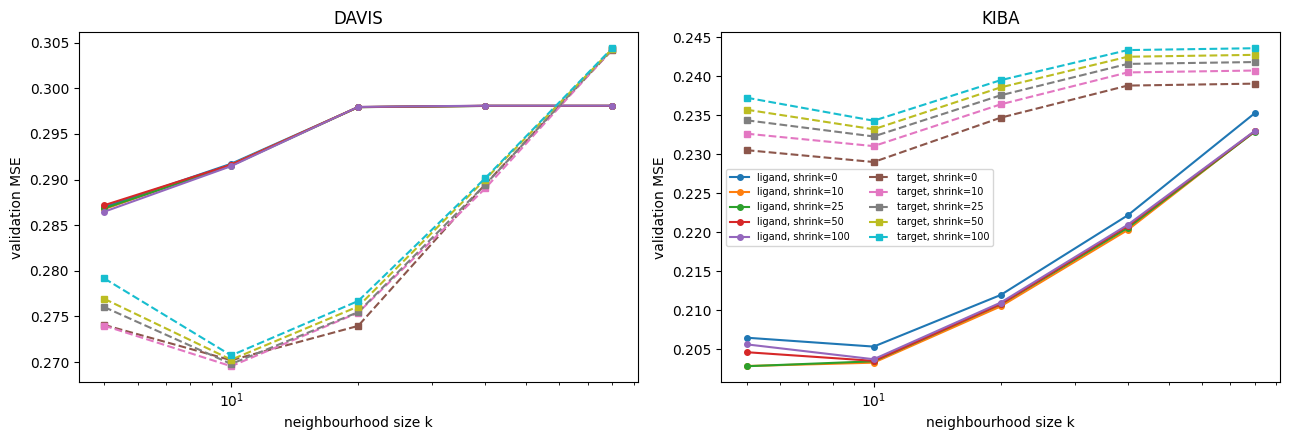

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, sub) in zip(axes, search.groupby("dataset")):
    for (axis, shrinkage), part in sub.groupby(["axis", "shrinkage"]):
        style = "-o" if axis == "ligand" else "--s"
        ax.plot(part["k"], part["val MSE"], style, markersize=4,
                label=f"{axis}, shrink={shrinkage:g}")
    ax.set_xscale("log")
    ax.set_xlabel("neighbourhood size k")
    ax.set_ylabel("validation MSE")
    ax.set_title(name)
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("figures/task2_cf_grid.png", dpi=200)
plt.show()

In [14]:
mf_grid = [{"n_factors": f, "reg": reg} for f in [8, 16] for reg in [0.05, 0.10]]
mf_search = []
mf_best = {}
for name, frame in frames.items():
    rows, cols, y_true = frame.xy("val")
    for params in mf_grid:
        model = MatrixFactorisationCF(epochs=25, **params).fit(frame)
        y_pred = model.predict(rows, cols)
        mf_search.append({"dataset": name, **params,
                          "val MSE": mse(y_true, y_pred),
                          "val CI": concordance_index(y_true, y_pred)})
    sub = pd.DataFrame(mf_search)
    sub = sub[sub["dataset"] == name]
    row = sub.loc[sub["val MSE"].idxmin()]
    mf_best[name] = {"n_factors": int(row["n_factors"]), "reg": float(row["reg"])}
    print(f"{name}: best MF {mf_best[name]} -> val MSE {row['val MSE']:.4f}")

pd.DataFrame(mf_search).round(4)

DAVIS: best MF {'n_factors': 16, 'reg': 0.05} -> val MSE 0.3138
KIBA: best MF {'n_factors': 16, 'reg': 0.05} -> val MSE 0.2615


,dataset,n_factors,reg,val MSE,val CI
0,DAVIS,8,0.05,0.3291,0.8508
1,DAVIS,8,0.10,0.3947,0.8212
2,DAVIS,16,0.05,0.3138,0.8565
3,DAVIS,16,0.10,0.3680,0.8334
4,KIBA,8,0.05,0.2684,0.8178
5,KIBA,8,0.10,0.3052,0.8003
6,KIBA,16,0.05,0.2615,0.8213
7,KIBA,16,0.10,0.3041,0.8019


## 5. Final evaluation

Every model is refitted on the training partition with its selected hyperparameters and evaluated once on train, validation and test. The neighbourhood CF model is the one carried forward as the Task 2 recommender; the others are the comparison set.

In [15]:
models = {}
for name, frame in frames.items():
    models[name] = {
        "global mean": ConstantModel("global").fit(frame),
        "ligand mean": ConstantModel("ligand").fit(frame),
        "target mean": ConstantModel("target").fit(frame),
        "bias": BiasModel().fit(frame),
        "CF neighbourhood": NeighbourhoodCF(**best_params[name]).fit(frame),
        "CF matrix factorisation": MatrixFactorisationCF(epochs=25, **mf_best[name]).fit(frame),
    }

results = []
for name, frame in frames.items():
    for label, model in models[name].items():
        scores = evaluate(model, frame)
        for part in ["train", "val", "test"]:
            results.append({"dataset": name, "model": label, "split": part,
                            **scores.loc[part].to_dict()})

results = pd.DataFrame(results)
columns = ["MSE", "CI", "Hit@1", "Hit@5", "MRR", "Hit@1 random", "Hit@5 random"]
results[columns] = results[columns].astype(float)
results.set_index(["dataset", "model", "split"])[columns].round(4)

MSE      CI   Hit@1   Hit@5     MRR  \
dataset model                   split                                           
DAVIS   global mean             train  0.6594     NaN  0.0000  0.0294  0.0240   
                                val    0.6685     NaN  0.0588  0.1176  0.1110   
                                test   0.6417     NaN  0.1029  0.1176  0.1432   
        ligand mean             train  0.4851  0.7694  0.0000  0.0294  0.0240   
                                val    0.4908  0.7624  0.0588  0.1176  0.1110   
                                test   0.4708  0.7712  0.1029  0.1176  0.1432   
        target mean             train  0.5873  0.6705  0.0735  0.2059  0.1527   
                                val    0.6306  0.6331  0.1765  0.4265  0.2902   
                                test   0.5945  0.6421  0.1618  0.3676  0.2617   
        bias                    train  0.4147  0.8134  0.0735  0.2206  0.1593   
                                val    0.4392  0.7969  0.1471  0.3971  0.2782   
                                test   0.4206  0.8024  0.1765  0.3676  0.2797   
        CF neighbourhood        train  0.1334  0.9181  0.2206  0.5735  0.3802   
                                val    0.2696  0.8710  0.2941  0.5882  0.4394   
                                test   0.2668  0.8688  0.3382  0.6471  0.4671   
        CF matrix factorisation train  0.2400  0.8881  0.1765  0.4412  0.3104   
                                val    0.3138  0.8565  0.3235  0.5735  0.4414   
                                test   0.3082  0.8581  0.2206  0.4853  0.3584   
KIBA    global mean             train  0.7032     NaN  0.2082  0.3969  0.3072   
                                val    0.6825     NaN  0.1513  0.4728  0.3123   
                                test   0.6770     NaN  0.1191  0.4715  0.2904   
        ligand mean             train  0.4039  0.7154  0.2082  0.3969  0.3072   
                                val    0.4277  0.6983  0.1513  0.4728  0.3123   
                                test   0.4192  0.7036  0.1191  0.4715  0.2904   
        target mean             train  0.6033  0.6834  0.2087  0.5056  0.3512   
                                val    0.5937  0.6822  0.2166  0.6301  0.4003   
                                test   0.5815  0.6823  0.2312  0.6416  0.4152   
        bias                    train  0.3500  0.7879  0.1783  0.5007  0.3348   
                                val    0.3697  0.7755  0.2275  0.6251  0.4060   
                                test   0.3557  0.7809  0.2402  0.6496  0.4206   
        CF neighbourhood        train  0.1231  0.8894  0.5884  0.9015  0.7260   
                                val    0.2029  0.8573  0.4599  0.8358  0.6275   
                                test   0.1916  0.8585  0.4605  0.8438  0.6238   
        CF matrix factorisation train  0.2074  0.8469  0.3337  0.6948  0.4947   
                                val    0.2615  0.8213  0.3551  0.7695  0.5348   
                                test   0.2486  0.8249  0.3644  0.7688  0.5438   

                                       Hit@1 random  Hit@5 random  
dataset model                   split                              
DAVIS   global mean             train        0.0038        0.0189  
                                val          0.0179        0.0893  
                                test         0.0178        0.0890  
        ligand mean             train        0.0038        0.0189  
                                val          0.0179        0.0893  
                                test         0.0178        0.0890  
        target mean             train        0.0038        0.0189  
                                val          0.0179        0.0893  
                                test         0.0178        0.0890  
        bias                    train        0.0038        0.0189  
                                val          0.0179        0.0893  
                                test         0.0178        0.0890  
        CF 

In [16]:
test_table = (results[results["split"] == "test"]
              .set_index(["dataset", "model"])[columns + ["ligands scored"]].round(4))
test_table

MSE      CI   Hit@1   Hit@5     MRR  \
dataset model                                                             
DAVIS   global mean              0.6417     NaN  0.1029  0.1176  0.1432   
        ligand mean              0.4708  0.7712  0.1029  0.1176  0.1432   
        target mean              0.5945  0.6421  0.1618  0.3676  0.2617   
        bias                     0.4206  0.8024  0.1765  0.3676  0.2797   
        CF neighbourhood         0.2668  0.8688  0.3382  0.6471  0.4671   
        CF matrix factorisation  0.3082  0.8581  0.2206  0.4853  0.3584   
KIBA    global mean              0.6770     NaN  0.1191  0.4715  0.2904   
        ligand mean              0.4192  0.7036  0.1191  0.4715  0.2904   
        target mean              0.5815  0.6823  0.2312  0.6416  0.4152   
        bias                     0.3557  0.7809  0.2402  0.6496  0.4206   
        CF neighbourhood         0.1916  0.8585  0.4605  0.8438  0.6238   
        CF matrix factorisation  0.2486  0.8249  0.3644  0.7688  0.5438   

                                 Hit@1 random  Hit@5 random  ligands scored  
dataset model                                                                
DAVIS   global mean                    0.0178        0.0890            68.0  
        ligand mean                    0.0178        0.0890            68.0  
        target mean                    0.0178        0.0890            68.0  
        bias                           0.0178        0.0890            68.0  
        CF neighbourhood               0.0178        0.0890            68.0  
        CF matrix factorisation        0.0178        0.0890            68.0  
KIBA    global mean                    0.0795        0.3975           999.0  
        ligand mean                    0.0795        0.3975           999.0  
        target mean                    0.0795        0.3975           999.0  
        bias                           0.0795        0.3975           999.0  
        CF neighbourhood               0.0795        0.3975           999.0  
        CF matrix factorisation        0.0795        0.3975           999.0

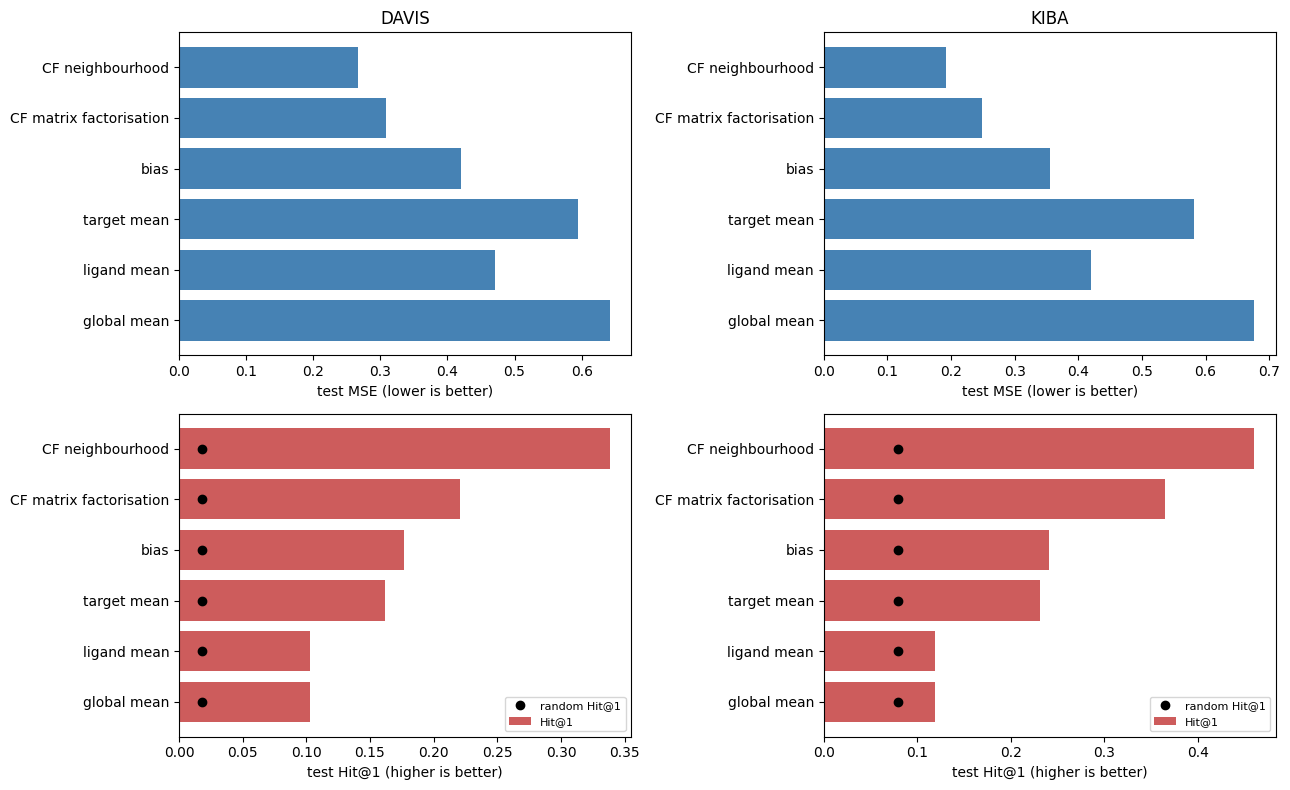

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
order = ["global mean", "ligand mean", "target mean", "bias",
         "CF matrix factorisation", "CF neighbourhood"]
for col, name in enumerate(frames):
    sub = results[(results["dataset"] == name) & (results["split"] == "test")].set_index("model")
    sub = sub.loc[order]
    axes[0, col].barh(order, sub["MSE"], color="steelblue")
    axes[0, col].set_xlabel("test MSE (lower is better)")
    axes[0, col].set_title(name)
    axes[1, col].barh(order, sub["Hit@1"], color="indianred", label="Hit@1")
    axes[1, col].plot(sub["Hit@1 random"], order, "ko", label="random Hit@1")
    axes[1, col].set_xlabel("test Hit@1 (higher is better)")
    axes[1, col].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/task2_model_comparison.png", dpi=200)
plt.show()

In [18]:
fallback = []
for name, frame in frames.items():
    model = models[name]["CF neighbourhood"]
    row = {"dataset": name, "axis": best_params[name]["axis"], "k": best_params[name]["k"]}
    for part in ["train", "val", "test"]:
        row[f"{part} fallback"] = model.fallback_rate(frame, part)
    fallback.append(row)
pd.DataFrame(fallback).set_index("dataset").round(4)

,axis,k,train fallback,val fallback,test fallback
dataset,,,,,
DAVIS,target,10,0.0,0.0,0.0000
KIBA,ligand,5,0.0,0.0,0.0001


### Is the recommender necessary? 

**a) Known-answer lookup is not available.** Every evaluated pair is held out, so no model can read its score off the training matrix. The relevant "just look it up" strategy is the ligand's own training mean, i.e. `ligand mean`. Because that predictor is constant across a ligand's candidate targets, its ranking is uninformative and its Hit rates equal the random reference. The gap between CF and `ligand mean` in both MSE and Hit@1 is therefore the measurable value added by the collaborative signal.

**b) Sensitivity to training density.** The training partition is thinned to 10%, 25%, 50% and 100% of its observations (the validation and test partitions stay fixed) and CF is refitted. This shows how the benefit depends on how much of the matrix is filled, which is the structural difference between dense DAVIS and sparse KIBA.

In [19]:
def thin_frame(frame, keep, seed=SEED):
    rng = np.random.default_rng(seed)
    rows, cols, vals = frame.xy("train")
    mask = rng.random(len(vals)) < keep
    thinned = Frame.__new__(Frame)
    thinned.__dict__.update(frame.__dict__)
    thinned.parts = dict(frame.parts)
    thinned.parts["train"] = (rows[mask], cols[mask], vals[mask])
    thinned.R = np.full(frame.R.shape, np.nan)
    thinned.R[rows[mask], cols[mask]] = vals[mask]
    return thinned


density = []
for name, frame in frames.items():
    rows, cols, y_true = frame.xy("test")
    for keep in [0.10, 0.25, 0.50, 1.00]:
        thinned = thin_frame(frame, keep)
        cf = NeighbourhoodCF(**best_params[name]).fit(thinned)
        lig = ConstantModel("ligand").fit(thinned)
        cf_pred = cf.predict(rows, cols)
        density.append({
            "dataset": name, "training kept": keep,
            "observed share": float(np.isfinite(thinned.R).mean()),
            "CF MSE": mse(y_true, cf_pred),
            "ligand mean MSE": mse(y_true, lig.predict(rows, cols)),
            "CF CI": concordance_index(y_true, cf_pred),
            "CF Hit@1": ranking_metrics(rows, y_true, cf_pred)["Hit@1"],
            "fallback": float(cf.fallbacks.mean()),
        })
density = pd.DataFrame(density)
density.set_index(["dataset", "training kept"]).round(4)

observed share  CF MSE  ligand mean MSE   CF CI  \
dataset training kept                                                    
DAVIS   0.10                   0.0677  0.6328           0.5005  0.7182   
        0.25                   0.1770  0.4379           0.4843  0.7899   
        0.50                   0.3484  0.3559           0.4749  0.8250   
        1.00                   0.7000  0.2668           0.4708  0.8688   
KIBA    0.10                   0.0172  0.5287           0.5739  0.7096   
        0.25                   0.0432  0.3815           0.4794  0.7735   
        0.50                   0.0864  0.2831           0.4419  0.8173   
        1.00                   0.1739  0.1916           0.4192  0.8585   

                       CF Hit@1  fallback  
dataset training kept                      
DAVIS   0.10             0.0147    0.0569  
        0.25             0.1324    0.0000  
        0.50             0.1912    0.0000  
        1.00             0.3382    0.0000  
KIBA    0.10             0.1832    0.1039  
        0.25             0.2733    0.0176  
        0.50             0.3383    0.0011  
        1.00             0.4605    0.0001

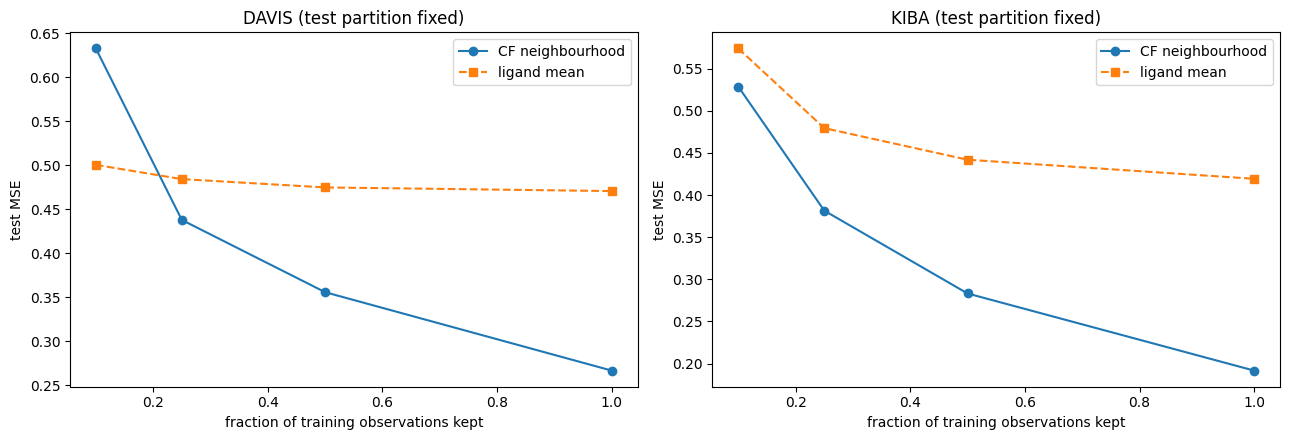

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, sub) in zip(axes, density.groupby("dataset")):
    ax.plot(sub["training kept"], sub["CF MSE"], "-o", label="CF neighbourhood")
    ax.plot(sub["training kept"], sub["ligand mean MSE"], "--s", label="ligand mean")
    ax.set_xlabel("fraction of training observations kept")
    ax.set_ylabel("test MSE")
    ax.set_title(f"{name} (test partition fixed)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/task2_density.png", dpi=200)
plt.show()

## 6. Save the models

Each dataset's neighbourhood CF model is saved as `saved_models/{dataset}_cf.npz`. Preserve learned CF state and score-scale information. Verify that reloading reproduces predictions.

In [21]:
SCORE_NAMES = {"DAVIS": "pKd = 9 - log10(Kd[nM])", "KIBA": "KIBA score"}


def save_cf(model, frame, name, path):
    rows, cols, vals = frame.xy("train")
    np.savez_compressed(
        path,
        ligands=frame.ligands, targets=frame.targets,
        mu=model.bias.mu, b_lig=model.bias.b_lig, b_tgt=model.bias.b_tgt,
        residuals=model.E, observed=model.O, similarity=model.similarity,
        k=model.k, shrinkage=model.shrinkage, axis=model.axis, reg=model.reg,
        dataset=name, score_name=SCORE_NAMES[name], split_seed=SEED,
        score_min=vals.min(), score_max=vals.max(),
        score_mean=vals.mean(), score_std=vals.std(),
    )
    return path


class LoadedCF:
    def __init__(self, path):
        store = np.load(path, allow_pickle=False)
        self.ligands = store["ligands"].astype(str)
        self.targets = store["targets"].astype(str)
        self.lig_pos = {v: i for i, v in enumerate(self.ligands)}
        self.tgt_pos = {v: i for i, v in enumerate(self.targets)}
        self.E = store["residuals"]
        self.O = store["observed"]
        self.similarity = store["similarity"]
        self.k = int(store["k"])
        self.shrinkage = float(store["shrinkage"])
        self.axis = str(store["axis"])
        self.dataset = str(store["dataset"])
        self.score_name = str(store["score_name"])
        self.scale = {key: float(store[f"score_{key}"])
                      for key in ["min", "max", "mean", "std"]}
        self.baseline = (float(store["mu"]) + store["b_lig"][:, None]
                         + store["b_tgt"][None, :])

    _oriented = NeighbourhoodCF._oriented
    predict = NeighbourhoodCF.predict

    def predict_ids(self, ligand_ids, target_ids):
        rows = np.array([self.lig_pos[v] for v in np.atleast_1d(ligand_ids)])
        cols = np.array([self.tgt_pos[v] for v in np.atleast_1d(target_ids)])
        return self.predict(rows, cols)

    def recommend(self, ligand_id, target_ids):
        target_ids = np.asarray(target_ids, dtype=str)
        predictions = self.predict_ids(np.repeat(ligand_id, len(target_ids)), target_ids)
        table = pd.DataFrame({"target_id": target_ids, "predicted": predictions,
                              "fallback": self.fallbacks})
        table = table.sort_values("predicted", ascending=False, kind="stable")
        table.insert(0, "predicted rank", np.arange(1, len(table) + 1))
        return table.reset_index(drop=True)

In [22]:
paths = {}
for name, frame in frames.items():
    path = f"saved_models/{name.lower()}_cf.npz"
    paths[name] = save_cf(models[name]["CF neighbourhood"], frame, name, path)
    print(f"{name}: saved {path} ({os.path.getsize(path) / 1e6:.2f} MB)")

loaded = {name: LoadedCF(path) for name, path in paths.items()}
for name, frame in frames.items():
    rows, cols, _ = frame.xy("test")
    before = models[name]["CF neighbourhood"].predict(rows, cols)
    after = loaded[name].predict(rows, cols)
    print(f"{name}: reload reproduces predictions = {np.allclose(before, after, atol=1e-12)}"
          f", max abs difference {np.abs(before - after).max():.2e}")
    print(f"       score scale: {loaded[name].score_name}, "
          f"train range [{loaded[name].scale['min']:.3f}, {loaded[name].scale['max']:.3f}], "
          f"mean {loaded[name].scale['mean']:.3f}, std {loaded[name].scale['std']:.3f}")

DAVIS: saved saved_models/davis_cf.npz (1.24 MB)
KIBA: saved saved_models/kiba_cf.npz (29.32 MB)
DAVIS: reload reproduces predictions = True, max abs difference 0.00e+00
       score scale: pKd = 9 - log10(Kd[nM]), train range [5.000, 10.620], mean 5.395, std 0.812
KIBA: reload reproduces predictions = True, max abs difference 0.00e+00
       score scale: KIBA score, train range [0.000, 17.200], mean 11.721, std 0.839


## 7. Case study

### Choice of the three fixed ligands per dataset

Candidates were screened on the training and test partitions only (no model involved in the screening rule) with three requirements, and the three fixed ligands per dataset were chosen to cover three different regimes:

1. at least 6 held-out candidate targets, so that `Hit@5` is not trivially satisfied;
2. a non-degenerate held-out range, so that a unique "true best target" exists and CI is defined;
3. one ligand each from a **selective**, a **flat / screening-limit** and an **extreme** regime (promiscuous strong binder for DAVIS, severely under-measured row for KIBA), so that the set contains both successes and failures rather than three variations of the same situation.

The resulting fixed sets are:

| dataset | ligand | regime |
|---|---|---|
| DAVIS | `11338033` | selective ligand with one real hit in a row otherwise at the screening limit (also a sheet example) |
| DAVIS | `3038525` | nearly flat row (training std 0.12, 94.5% of held-out targets at pKd 5) that nevertheless hides one strong interaction |
| DAVIS | `44259` | promiscuous strong binder, widest held-out range in the dataset (also a sheet example) |
| KIBA | `CHEMBL1991678` | well-measured row (100 training pairs) with a wide held-out range |
| KIBA | `CHEMBL1163016` | extreme sparsity: only 6 training measurements |
| KIBA | `CHEMBL1965845` | well-measured row where the recommender fails despite ample neighbours |

The six ligands named in the sheet are also evaluated at the end of this section, so nothing is lost by the substitution.

In [23]:
CASES = {
    "DAVIS": ["11338033", "3038525", "44259"],
    "KIBA": ["CHEMBL1991678", "CHEMBL1163016", "CHEMBL1965845"],
}
SHEET_CASES = {
    "DAVIS": ["10127622", "11338033", "44259"],
    "KIBA": ["CHEMBL1967538", "CHEMBL2004544", "CHEMBL565612"],
}

test_pairs = {name: df[df["split"] == "test"] for name, df in splits.items()}
train_pairs = {name: df[df["split"] == "train"] for name, df in splits.items()}


def ligand_profile(name, ligand_id):
    train_rows = train_pairs[name][train_pairs[name]["ligand_id"] == ligand_id]
    test_rows = test_pairs[name][test_pairs[name]["ligand_id"] == ligand_id]
    return {
        "dataset": name, "ligand": ligand_id,
        "train measurements": len(train_rows),
        "train mean": train_rows["score"].mean(),
        "train std": train_rows["score"].std(),
        "test candidates": len(test_rows),
        "test min": test_rows["score"].min(),
        "test max": test_rows["score"].max(),
        "share at test minimum": (test_rows["score"] == test_rows["score"].min()).mean(),
    }


pd.DataFrame([ligand_profile(name, ligand_id)
              for name, ligand_ids in CASES.items() for ligand_id in ligand_ids]
             ).set_index(["dataset", "ligand"]).round(3)

train measurements  train mean  train std  \
dataset ligand                                                     
DAVIS   11338033                      264       5.203      0.704   
        3038525                       263       5.021      0.119   
        44259                         248       7.229      1.243   
KIBA    CHEMBL1991678                 100      11.547      0.411   
        CHEMBL1163016                   6      12.439      1.860   
        CHEMBL1965845                  89      12.057      0.763   

                       test candidates  test min  test max  \
dataset ligand                                               
DAVIS   11338033                    57     5.000     9.022   
        3038525                     55     5.000     8.553   
        44259                       71     5.000    10.432   
KIBA    CHEMBL1991678               26    11.100    16.000   
        CHEMBL1163016                9    10.401    14.401   
        CHEMBL1965845               25    11.100    13.300   

                       share at test minimum  
dataset ligand                                
DAVIS   11338033                       0.912  
        3038525                        0.945  
        44259                          0.085  
KIBA    CHEMBL1991678                  0.038  
        CHEMBL1163016                  0.556  
        CHEMBL1965845                  0.040

In [24]:
def case_report(model, name, ligand_id, top=10):
    truth = test_pairs[name]
    truth = truth[truth["ligand_id"] == ligand_id][["target_id", "score"]]
    table = model.recommend(ligand_id, truth["target_id"].to_numpy())
    table = table.merge(truth.rename(columns={"score": "true"}), on="target_id")
    best_rank = int(table.loc[table["true"].idxmax(), "predicted rank"])
    table["label"] = np.where(table["true"] == table["true"].max(), "correct", "wrong")
    table["true rank"] = (-table["true"]).rank(method="min").astype(int)

    metrics = {
        "candidates": len(table),
        "MSE": mse(table["true"], table["predicted"]),
        "CI": concordance_index(table["true"], table["predicted"]),
        "rank of true best target": best_rank,
        "Hit@1": float(best_rank <= 1),
        "Hit@5": float(best_rank <= 5),
        "reciprocal rank": 1 / best_rank,
        "fallback predictions": float(table["fallback"].mean()),
    }
    shown = pd.concat([table.head(top), table[table["label"] == "correct"]]).drop_duplicates()
    return metrics, shown.sort_values("predicted rank")


case_metrics = []
for name, ligand_ids in CASES.items():
    for ligand_id in ligand_ids:
        metrics, shown = case_report(loaded[name], name, ligand_id)
        case_metrics.append({"dataset": name, "ligand": ligand_id, **metrics})
        print(f"=== {name} ligand {ligand_id}: "
              f"{metrics['candidates']} held-out candidate targets, "
              f"true best target ranked {metrics['rank of true best target']} ===")
        print(shown[["predicted rank", "target_id", "predicted", "true",
                      "true rank", "label", "fallback"]].round(3).to_string(index=False))
        print()

pd.DataFrame(case_metrics).set_index(["dataset", "ligand"]).round(4)

=== DAVIS ligand 11338033: 57 held-out candidate targets, true best target ranked 1 ===
 predicted rank            target_id  predicted  true  true rank   label  fallback
              1                PCTK2      7.686 9.022          1 correct     False
              2                HIPK3      6.252 5.000          6   wrong     False
              3                HIPK2      6.203 5.000          6   wrong     False
              4 PFCDPK1(Pfalciparum)      5.802 5.000          6   wrong     False
              5                MKNK2      5.749 5.000          6   wrong     False
              6                HIPK1      5.524 5.000          6   wrong     False
              7                 CLK1      5.360 6.004          4   wrong     False
              8                 DDR1      5.357 5.000          6   wrong     False
              9                IRAK1      5.255 5.000          6   wrong     False
             10                PRKG1      5.242 5.000          6   wrong     False

candidates     MSE      CI  rank of true best target  \
dataset ligand                                                                
DAVIS   11338033               57  0.2380  0.7556                         1   
        3038525                55  0.2569  0.7862                        33   
        44259                  71  0.9307  0.7126                         3   
KIBA    CHEMBL1991678          26  0.1883  0.9286                         1   
        CHEMBL1163016           9  1.9693  0.8000                         1   
        CHEMBL1965845          25  0.1981  0.7518                        23   

                       Hit@1  Hit@5  reciprocal rank  fallback predictions  
dataset ligand                                                              
DAVIS   11338033         1.0    1.0           1.0000                   0.0  
        3038525          0.0    0.0           0.0303                   0.0  
        44259            0.0    1.0           0.3333                   0.0  
KIBA    CHEMBL1991678    1.0    1.0           1.0000                   0.0  
        CHEMBL1163016    1.0    1.0           1.0000                   0.0  
        CHEMBL1965845    0.0    0.0           0.0435                   0.0

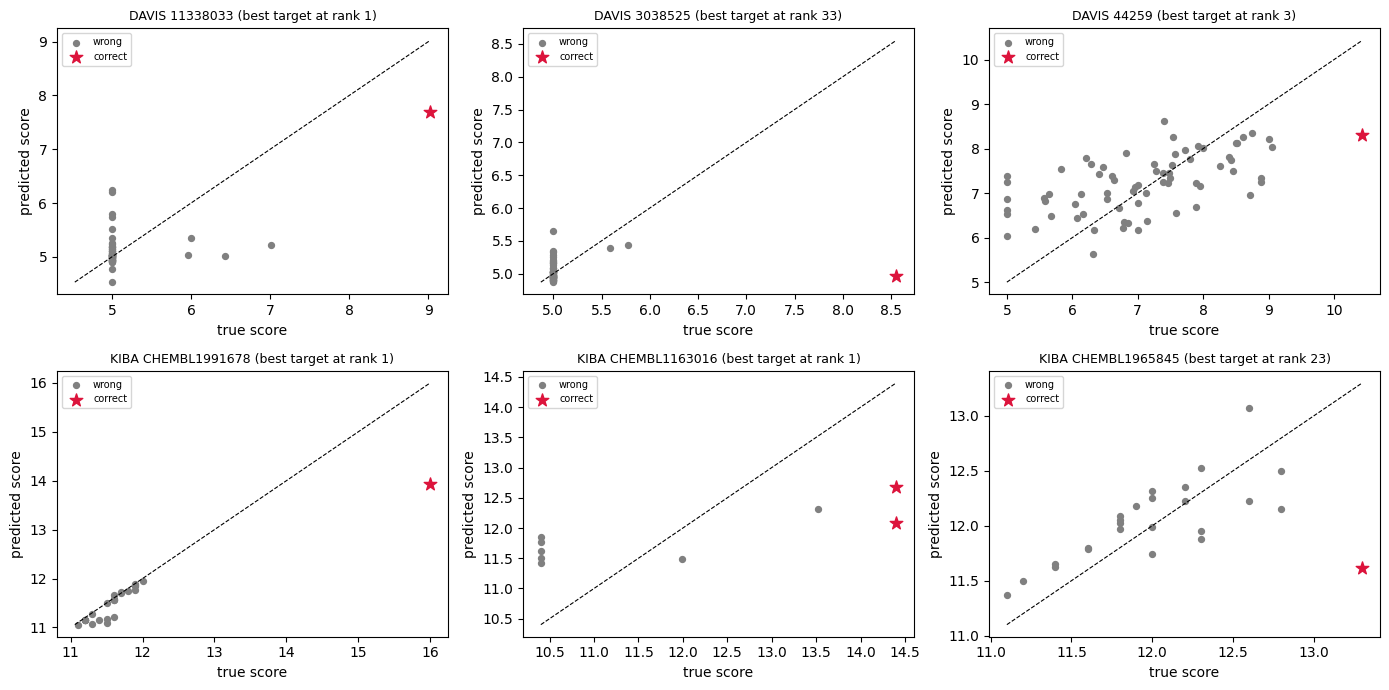

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, (name, ligand_ids) in enumerate(CASES.items()):
    for col, ligand_id in enumerate(ligand_ids):
        truth = test_pairs[name]
        truth = truth[truth["ligand_id"] == ligand_id][["target_id", "score"]]
        table = loaded[name].recommend(ligand_id, truth["target_id"].to_numpy())
        table = table.merge(truth.rename(columns={"score": "true"}), on="target_id")
        correct = table["true"] == table["true"].max()
        ax = axes[row, col]
        ax.scatter(table.loc[~correct, "true"], table.loc[~correct, "predicted"],
                   s=18, color="grey", label="wrong")
        ax.scatter(table.loc[correct, "true"], table.loc[correct, "predicted"],
                   s=90, color="crimson", marker="*", label="correct")
        limits = [table[["true", "predicted"]].min().min(),
                  table[["true", "predicted"]].max().max()]
        ax.plot(limits, limits, "k--", linewidth=0.8)
        rank = int(table.loc[table["true"].idxmax(), "predicted rank"])
        ax.set_title(f"{name} {ligand_id} (best target at rank {rank})", fontsize=9)
        ax.set_xlabel("true score")
        ax.set_ylabel("predicted score")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("figures/task2_case_study.png", dpi=200)
plt.show()

## 8. Discussion

### What the numbers say

On test data the neighbourhood CF model is the best model on both datasets and on every metric:

| dataset | model | MSE | CI | Hit@1 | Hit@5 |
|---|---|---|---|---|---|
| DAVIS | ligand mean (lookup baseline) | 0.471 | 0.771 | 0.103 | 0.118 |
| DAVIS | bias (`mu + b_lig + b_tgt`) | 0.421 | 0.802 | 0.177 | 0.368 |
| DAVIS | CF matrix factorisation | 0.308 | 0.858 | 0.221 | 0.485 |
| DAVIS | **CF neighbourhood** | **0.267** | **0.869** | **0.338** | **0.647** |
| KIBA | ligand mean (lookup baseline) | 0.419 | 0.704 | 0.119 | 0.472 |
| KIBA | bias (`mu + b_lig + b_tgt`) | 0.356 | 0.781 | 0.240 | 0.650 |
| KIBA | CF matrix factorisation | 0.249 | 0.825 | 0.364 | 0.769 |
| KIBA | **CF neighbourhood** | **0.192** | **0.859** | **0.461** | **0.844** |

The random reference for Hit@1 is 0.018 on DAVIS and 0.080 on KIBA, so the ranking quality is far above chance. Validation and test numbers are close on both datasets (DAVIS 0.270 vs 0.267 MSE, KIBA 0.203 vs 0.192), so the hyperparameter choice did not overfit the validation partition. Training MSE is much lower than test MSE for the neighbourhood model (0.133 and 0.123), which is expected: a training pair is predicted from neighbours that were themselves fitted around it.

Validation selected different similarity axes for the two datasets, which follows from their shapes. DAVIS has 68 ligands and 379 targets, so target-target similarity (`axis="target"`, k = 10) is estimated from 68-dimensional profiles that are 70% filled, and it wins. KIBA has 2,068 ligands and 229 targets, so ligand-ligand similarity (`axis="ligand"`, k = 5) has many more candidate neighbours to choose from, and the small k with shrinkage 25 reflects that only the few most similar ligands carry usable signal.

### Is the recommender necessary here?

Yes on both datasets, and the evidence is held-out rather than asserted.

Every evaluated pair was removed from training, so nothing can be looked up. The honest "query of known answers" strategy is `ligand mean`, the ligand's average training score, which is also exactly what CF degrades to when no neighbour is available. CF reduces its test MSE by 43% on DAVIS (0.471 to 0.267) and 54% on KIBA (0.419 to 0.192). More importantly, `ligand mean` predicts one constant per ligand, so it cannot order that ligand's candidate targets at all: its Hit@1 equals the random reference. CF reaches 0.338 and 0.461. The ranking ability therefore comes entirely from the interaction term, not from knowing which ligands are strong binders in general. The same holds against `bias`, which knows ligand promiscuity and target bindability but no interaction, and which CF beats by 0.154 MSE on DAVIS and 0.164 on KIBA.

The density experiment qualifies the conclusion. When the training partition is thinned, CF loses its advantage and at the extreme becomes *worse* than the trivial baseline: at 10% of DAVIS training data (6.8% of the matrix observed) CF scores 0.633 MSE against 0.501 for `ligand mean`, because the surviving neighbour sets are too small for the similarities to be meaningful. On KIBA the crossover is similar (0.529 vs 0.574 at 10% kept, i.e. 1.7% of the matrix). So the recommender is necessary and useful at the densities these benchmarks actually have, but it is not unconditionally better than averaging; there is a density below which neighbourhood CF should be replaced by the baseline, and shrinkage is what keeps the degradation graceful rather than catastrophic.

### Sparsity, missing values and abnormal records

*Missing entries.* On KIBA 75.2% of the matrix is unmeasured, and after the split only 17.4% of entries are available for fitting. Missing is not zero: an unmeasured pair carries no evidence of non-binding, so similarities are computed over co-measured entries only and the shrinkage factor `n_common / (n_common + shrinkage)` discounts pairs that overlap on few targets. Without it, two ligands sharing three measurements could be declared near-identical and dominate the neighbour average; with shrinkage 25 chosen on validation, KIBA's best k drops to 5, which says that only strongly-overlapping neighbours are worth listening to.

*Available neighbours and fallback.* At full training density the fallback almost never fires (0.00% on DAVIS, 0.01% on KIBA), because a queried target usually has at least one other ligand measured against it. Thinning exposes the mechanism: fallback rises to 5.7% on DAVIS and 10.4% on KIBA at 10% of training data, and those predictions are flat per ligand, which is precisely why both MSE and Hit@1 collapse there. This is also the limitation that Task 3 addresses - a target with no training measurements at all has an empty neighbour pool by construction, so the prediction can only be the ligand's mean and cannot distinguish one unseen target from another.

*Abnormal values.* DAVIS reports a large mass of records at the screening limit Kd = 10,000 nM, i.e. pKd = 5, and KIBA contains exact zeros. These were kept, as required in Task 1, and they have two visible effects. First, they create heavy ties in the true scores, which the CI handles explicitly: tied pairs are excluded from the comparable count A, so CI measures ordering only where the truth actually distinguishes two pairs. Second, they make a ligand's row nearly constant, which caps what any recommender can achieve for that ligand - see ligand `10127622` below.

### Case study

**DAVIS `11338033`** (264 training measurements, training std 0.70) is the clean success and the type of case a recommender is meant to handle. Of its 57 held-out targets, 91% sit at the screening limit 5.00, so there is exactly one interaction worth finding: PCTK2, true pKd 9.02. CF ranks it 1 and predicts 7.69, well clear of the next candidate at 6.25 (MSE 0.238, CI 0.756). The neighbours of this ligand agreed on PCTK2, and that agreement was enough to lift a single hit out of a flat row.

**DAVIS `3038525`** (263 training measurements, training std 0.12) is the same situation with the opposite outcome, and is the most instructive failure in the set. The row is almost perfectly flat - 94.5% of its 55 held-out targets are at pKd 5.00 - but it hides one strong interaction, p38-alpha at 8.55. CF ranks that target **33rd of 55** and predicts 4.97 for it, i.e. slightly *below* the row's own plateau, while the top of its list is filled with targets that are truly inactive. Per-pair MSE stays low (0.257) and CI is respectable (0.786) precisely because almost every pair is a correctly predicted 5.00. This is the characteristic blind spot of neighbourhood CF: an isolated strong interaction leaves no trace in the ligand's own residual profile, so if the neighbours of that target do not happen to share the interaction, nothing in the model can recover it. Aggregate MSE and CI look fine while the one decision that matters is wrong.

**DAVIS `44259`** (training mean 7.23, std 1.24) is a promiscuous strong binder with the widest held-out range in the dataset, 5.00 to 10.43 over 71 candidates. It has the worst per-case MSE (0.931) and a middling CI (0.713): the model correctly recognises that many targets are bound strongly, but compresses the top of the scale and ranks the true best target LOK (10.43) third, predicting 8.30. Promiscuity hurts for the opposite reason to the flat row - almost everything binds, so neighbour agreement carries little discriminative information about which target binds *best*.

**KIBA `CHEMBL1991678`** (100 training measurements, 26 candidates) is the best KIBA case: the true best target Q16539 (16.00) is ranked 1 and the rest of the list is correctly ordered around a tight plateau near 11.9 (MSE 0.188, CI 0.929, the highest per-case CI here). Note that the predicted value for the winner, 13.92, still undershoots the truth by over two units - the ranking is right while the magnitude is conservative, which is the expected behaviour of a shrunken weighted average.

**KIBA `CHEMBL1163016`** (6 training measurements, 9 candidates) is the extreme-sparsity case, chosen to replace the sheet's `CHEMBL1967538` which keeps only two held-out targets. With six training observations the ligand's bias and its similarities are estimated from almost nothing, and the per-case MSE is the worst of all six (1.969). Yet the ordering largely survives: two targets tie for the maximum at 14.401 (P06241 and P12931) and CF places them at ranks 1 and 3, with CI 0.800. The lesson is specific - severe sparsity destroys the predicted *scale* long before it destroys the predicted *order*, so on sparse rows the recommendation list can still be useful while the predicted affinity should not be quoted as a number.

**KIBA `CHEMBL1965845`** (89 training measurements, 25 candidates) is the KIBA analogue of DAVIS `3038525`: a well-measured row where CF nevertheless fails, ranking the true best target P35916 (13.30) **23rd of 25** and predicting 11.62 for it, while MSE stays at 0.198 and CI at 0.752. Neighbours were plentiful, so this is a genuine model error rather than a data limitation, and it confirms that good aggregate error across a row does not imply that the extreme value is found.

Across the six cases the pattern is consistent and rests on two conditions rather than one. Ranking succeeds when the true best target stands clearly above the ligand's plateau *and* that target's own column carries the interaction in other ligands (`11338033`, `CHEMBL1991678`). It fails when the strong interaction is an isolated outlier that no neighbour shares (`3038525`, `CHEMBL1965845`), and the predicted scale - not the order - is what degrades first under sparsity (`CHEMBL1163016`) or promiscuity (`44259`). Because two of the six fixed cases are outright ranking failures with perfectly healthy MSE, the case study also shows why Hit@k has to be reported next to MSE: a model can be accurate on 95% of a row and still miss the only pair a chemist would act on.

### Limitations

1. Scores are modelled from IDs only, so chemistry and sequence are unused. Two ligands with nearly identical structures are related only if they happen to share measured targets.
2. A ligand or target that is absent from training cannot be served at all; the fallback is the ligand mean, which is the cold-target problem Task 3 takes up.
3. The case ligands have between 9 and 71 held-out candidates, which is enough for Hit@5 to be meaningful but still small enough that a single per-ligand number is noisy; the dataset-level rates over 68 (DAVIS) and 999 (KIBA) scored ligands are the reliable figures. `CHEMBL1163016` also has two targets tied at its maximum score, so its "rank of the true best target" is the better of the two tied positions.
4. MSE treats a mistake at the screening limit and a mistake among strong binders alike, although only the latter matters for drug discovery. CI and the Hit rates partly compensate, which is why all three are reported together.
5. The split is random over pairs, which is the easiest regime. It measures the matrix-completion ability of the recommender, not generalisation to new chemistry or new protein families.